# Counterfactual Construction

Builds the counterfactual signal C(t) in which short-lasting hyperglycaemia (SLH) episodes are removed, and compares glucose metrics before and after.

Equivalent scripts: `python3 -m scripts.counterfactual.lininterp_stepbystep` (episode figure) and `python3 -m scripts.counterfactual.lininterp_45days` (45-day overview).

**Usage** — from the repository root, point the notebook at a data folder and open it
(the open BrisT1D example data converted to glucose-only files is enough: `make brist1d_run`):

```bash
CGM_DATA_ROOT=$PWD/example_data/BrisT1D/converted jupyter lab notebooks/
```

**Authors:** Guillaume Deside, Laura Symul, Philippe Lysy, Zain Syed

> **Illustration only.** This notebook is run on the open **BrisT1D-Open** example data (Gordon James et al. 2025, CC BY 4.0), converted by `make brist1d` to glucose-only files (mg/dL, 5-min grid; see the README). These are not the study data: the numbers and figures illustrate what the code does and are not expected to match the manuscript, nor are they findings about BrisT1D.

## Method

For an SLH episode with onset $t_{on}$ and offset $t_{off}$ and a zone-expansion offset $\delta$:

1. **Zone expansion** — extend the episode to $[t_{on}-\delta,\; t_{off}+\delta]$.
2. **Anchors** — take the lowest reading in $[t_{on}-\delta, t_{on}]$ (anchor A) and in $[t_{off}, t_{off}+\delta]$ (anchor B).
3. **Linear interpolation** $L(t)$ between anchor A and anchor B.
4. **Smoothing** — a centred rolling mean (`KERNEL_MIN` minutes) over the interpolated region gives the final $C(t)$.

Outside the replaced regions $C(t)$ equals the observed signal $G(t)$. Parameters are in
`src/counterfactual/counterfactual_config.py`.

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether Jupyter was started from the repo root or from notebooks/
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import (
    PATIENT_ID_COL, TIME_COL, GLUCOSE_COL, COL_FILEPATH, WINDOW_SUMMARY_CSV,
    COL_EPISODE_START, COL_EPISODE_END, COL_EPISODE_DURATION, COL_EPISODE_CLASSIFICATION,
    CLASSIFICATION_SLH,
)
from src.preprocessing.load_data import load_window_data
from src.preprocessing.timestep import detect_dominant_sampling_interval
from src.episodes.load_episodes import prepare_episode_data, load_patient_episodes
from src.counterfactual.counterfactual_config import APPLY_KERNEL, KERNEL_MIN, SELECTED_OFFSET_MIN
from src.counterfactual.build_counterfactual import (
    build_linear_interpolation, build_counterfactual, build_full_counterfactual_signal,
)
from src.metrics.metrics import compute_basic_statistics, compute_time_in_range_metrics

%matplotlib inline

OFFSET_MIN = SELECTED_OFFSET_MIN   # δ, minutes
print(f"δ = {OFFSET_MIN} min, smoothing = {KERNEL_MIN} min ({'on' if APPLY_KERNEL else 'off'})")

δ = 30 min, smoothing = 60 min (on)


## 2. Load a patient and its SLH episodes

The patient with the most SLH episodes in the sample is used.

In [2]:
windows = pd.read_csv(WINDOW_SUMMARY_CSV)

best = None
for _, row in windows.iterrows():
    eps = load_patient_episodes(row[PATIENT_ID_COL])
    n_slh = 0 if eps is None else int((eps[COL_EPISODE_CLASSIFICATION] == CLASSIFICATION_SLH).sum())
    if best is None or n_slh > best[0]:
        best = (n_slh, row, eps)

n_slh, row, episodes = best
patient_id = row[PATIENT_ID_COL]

df = prepare_episode_data(load_window_data(row[COL_FILEPATH]))
timestep_min = detect_dominant_sampling_interval(df)
slh = episodes[episodes[COL_EPISODE_CLASSIFICATION] == CLASSIFICATION_SLH].reset_index(drop=True)

print(f"Patient {patient_id}: {len(slh)} SLH episodes, time step {timestep_min:.0f} min")


def to_episode(r):
    """Row of the episode table -> the dict the counterfactual builders expect."""
    return {"onset_time": r[COL_EPISODE_START], "offset_time": r[COL_EPISODE_END],
            "duration_min": r[COL_EPISODE_DURATION]}


slh_episodes = [to_episode(r) for _, r in slh.iterrows()]
slh[[COL_EPISODE_START, COL_EPISODE_END, COL_EPISODE_DURATION]].head()

Patient P04: 43 SLH episodes, time step 5 min


,onset_time,offset_time,duration_min
0,2023-09-02 09:45:00,2023-09-02 10:30:00,40.0
1,2023-09-02 13:25:00,2023-09-02 13:30:00,10.0
2,2023-09-03 19:40:00,2023-09-03 19:55:00,20.0
3,2023-09-04 12:45:00,2023-09-04 13:25:00,45.0
4,2023-09-06 11:00:00,2023-09-06 11:30:00,35.0


## 3. One episode: anchors → interpolation → smoothing

In [3]:
episode = slh_episodes[0]

linear, anchors = build_linear_interpolation(df, episode, OFFSET_MIN, timestep_min)
final, _ = build_counterfactual(df, episode, OFFSET_MIN, timestep_min)

print(f"Anchor A: {anchors['t_a']:%H:%M}  {anchors['g_a']:.0f} mg/dL")
print(f"Anchor B: {anchors['t_b']:%H:%M}  {anchors['g_b']:.0f} mg/dL")

Anchor A: 09:15  135 mg/dL
Anchor B: 11:00  146 mg/dL


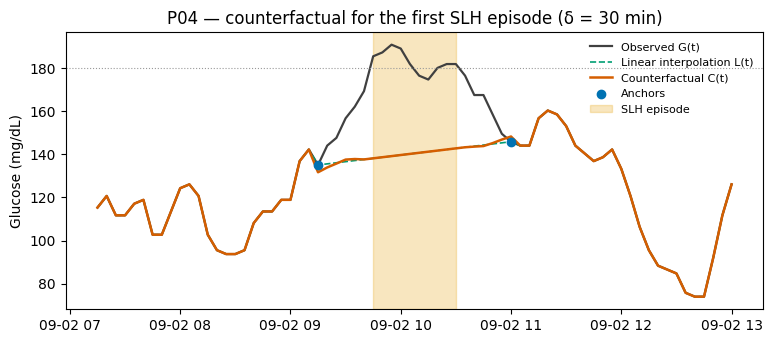

In [4]:
pad = pd.Timedelta(hours=2)
t, g = df[TIME_COL], df[GLUCOSE_COL].values
win = (t >= anchors["zone_start"] - pad) & (t <= anchors["zone_end"] + pad)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(t[win], g[win], color="0.25", lw=1.6, label="Observed G(t)")
ax.plot(t[win], linear[win], color="#009E73", lw=1.2, ls="--", label="Linear interpolation L(t)")
ax.plot(t[win], final[win], color="#D55E00", lw=1.8, label="Counterfactual C(t)")
ax.scatter([anchors["t_a"], anchors["t_b"]], [anchors["g_a"], anchors["g_b"]], color="#0072B2", zorder=5, label="Anchors")
ax.axvspan(episode["onset_time"], episode["offset_time"], color="#E69F00", alpha=0.25, label="SLH episode")
ax.axhline(180, color="0.6", ls=":", lw=0.8)
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title(f"{patient_id} — counterfactual for the first SLH episode (δ = {OFFSET_MIN} min)")
ax.legend(frameon=False, fontsize=8)
plt.show()

## 4. All SLH episodes of the window

In [5]:
counterfactual = build_full_counterfactual_signal(df, slh_episodes, OFFSET_MIN, timestep_min)

changed = ~np.isclose(counterfactual, df[GLUCOSE_COL].values)
print(f"{changed.sum()} of {len(df)} readings replaced ({changed.mean():.1%})")

765 of 12847 readings replaced (6.0%)


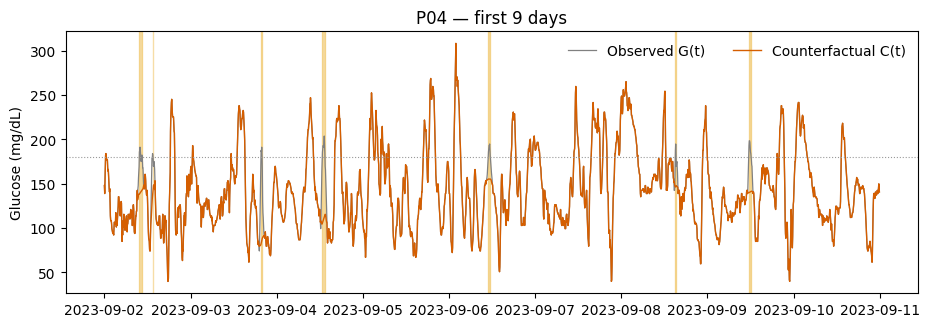

In [6]:
view = df[TIME_COL] < df[TIME_COL].min() + pd.Timedelta(days=9)

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(df.loc[view, TIME_COL], df.loc[view, GLUCOSE_COL], color="0.5", lw=0.9, label="Observed G(t)")
ax.plot(df.loc[view, TIME_COL], counterfactual[view.values], color="#D55E00", lw=1.0, label="Counterfactual C(t)")
for ep in slh_episodes:
    if ep["onset_time"] < df.loc[view, TIME_COL].max():
        ax.axvspan(ep["onset_time"], ep["offset_time"], color="#E69F00", alpha=0.35)
ax.axhline(180, color="0.6", ls=":", lw=0.8)
ax.set_ylabel("Glucose (mg/dL)")
ax.set_title(f"{patient_id} — first 9 days")
ax.legend(frameon=False, ncol=2)
plt.show()

## 5. Effect on glucose metrics

Every metric is computed on both signals; the counterfactual effect is the difference $\Delta = C - G$.

In [7]:
def summary_metrics(glucose):
    g = pd.Series(glucose).dropna()
    return {**compute_basic_statistics(g), **compute_time_in_range_metrics(g.values)}


original_m = summary_metrics(df[GLUCOSE_COL].values)
counterfactual_m = summary_metrics(counterfactual)

table = pd.DataFrame({"Observed": original_m, "Counterfactual": counterfactual_m}).dropna()
table["Δ (C − G)"] = table["Counterfactual"] - table["Observed"]
table.round(3)

,Observed,Counterfactual,Δ (C − G)
Mean_glycemia,142.100,139.800,-2.300
Median_glycemia,135.100,133.300,-1.800
Minimum_glycemia,39.600,39.600,0.000
Maximum_glycemia,353.200,353.200,0.000
SD,41.400,40.700,-0.700
CV,0.291,0.291,0.000
TIR70180,0.816,0.837,0.021
TIR70140,0.526,0.556,0.030
TIR60140,0.533,0.563,0.030
TBR70,0.012,0.012,0.000
